# Kural — Statistical Analysis and Business Patterns

This notebook conducts inferential statistical analysis and investigates operational patterns across financial products in the prepared complaint dataset (`complaints_clean.csv.gz`).

### Objectives
1. **Analysis A — Response Timeliness:** Test whether company timely-response rates differ across financial product categories.
2. **Analysis B — Recorded Relief:** Test how recorded company relief rates and relief types (monetary vs. non-monetary) vary across products.
3. **Analysis C — Narrative Length:** Test whether consumer complaint lengths (word counts) differ significantly across products.

### Methodological Notes & Limitations
- **Sample Scope:** This dataset contains 117,214 complaints from 2019 to January 9, 2020 where consumers provided consent to publish their narratives. It is an observational, published-narrative sample and not a random sample of all financial consumers.
- **Independence Assumption:** The presence of 10,854 duplicate narratives indicates shared templates, which may slightly weaken the assumption of observation independence.
- **No Causal Inference:** Statistical associations identified here describe empirical relationships; they do not imply that product category causes timeliness or relief outcomes.

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Directories
figures_dir = Path('../outputs/figures')
tables_dir = Path('../outputs/tables')
data_path = Path('../data/processed/complaints_clean.csv.gz')

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print(f"Data file exists: {data_path.exists()}")

Data file exists: True


In [2]:
# Load prepared dataset
df = pd.read_csv(data_path)
print(f"Loaded dataset: {len(df):,} records, {len(df.columns)} columns.")

# Verify has_recorded_relief feature
print("\nhas_recorded_relief distribution:")
print(df['has_recorded_relief'].value_counts(dropna=False))

print("\nReconciliation with company_response_to_consumer:")
cross_check = pd.crosstab(df['company_response_to_consumer'], df['has_recorded_relief'], margins=True)
display(cross_check)

Loaded dataset: 117,214 records, 26 columns.

has_recorded_relief distribution:
has_recorded_relief
False    95659
True     21555
Name: count, dtype: int64

Reconciliation with company_response_to_consumer:


has_recorded_relief,False,True,All
company_response_to_consumer,,,
Closed with explanation,94941,0,94941
Closed with monetary relief,0,5118,5118
Closed with non-monetary relief,0,16437,16437
Untimely response,718,0,718
All,95659,21555,117214


## Analysis A — Response Timeliness Across Products

### Business Question
Do response-timeliness rates differ across financial product categories?

### Hypotheses
- **Null Hypothesis ($H_0$):** Response timeliness is independent of the financial product category (timely response proportion is equal across products).
- **Alternative Hypothesis ($H_1$):** Response timeliness is dependent on the financial product category.

### Method
- **Contingency Table:** $9 \times 2$ table cross-tabulating product category and `timely_response` (Yes / No).
- **Test:** Pearson's Chi-Square Test of Independence (`scipy.stats.chi2_contingency`). Suitable for comparing categorical proportions across independent groups.
- **Expected Counts:** Verify all expected cell frequencies exceed 5.
- **Effect Size:** Cramer's $V = \sqrt{\frac{\chi^2}{n \cdot (\min(r, c) - 1)}} = \sqrt{\frac{\chi^2}{n}}$.
- **Confidence Intervals:** 95% Wilson score interval for each product's timely-response proportion. The Wilson interval provides accurate coverage for binomial proportions, especially when proportions are close to 1 (high timeliness).

*Note:* The `timely_response` field (Yes/No procedural timeliness) is analyzed here, which is distinct from the 718 complaints in the recorded response category `Untimely response`.

In [3]:
# 1. Calculate timeliness counts and proportions by product
pt_counts = df.groupby('product')['timely_response'].value_counts().unstack(fill_value=0)

# 95% Wilson confidence intervals
z = stats.norm.ppf(0.975)
n_a = pt_counts['Yes'] + pt_counts['No']
p_a = pt_counts['Yes'] / n_a
denom_a = 1 + z**2 / n_a
center_a = p_a + z**2 / (2 * n_a)
margin_a = z * np.sqrt((p_a * (1 - p_a) / n_a) + (z**2 / (4 * n_a**2)))

product_timeliness_stats = pd.DataFrame({
    'product': pt_counts.index,
    'total_complaints': n_a,
    'timely_count': pt_counts['Yes'],
    'untimely_count': pt_counts['No'],
    'timely_percentage': (p_a * 100).round(2),
    'ci_lower_pct': ((center_a - margin_a) / denom_a * 100).round(2),
    'ci_upper_pct': ((center_a + margin_a) / denom_a * 100).round(2)
}).sort_values('total_complaints', ascending=False).reset_index(drop=True)

# Export analytical table
product_timeliness_stats.to_csv(tables_dir / 'product_timeliness_statistics.csv', index=False)
print("Saved outputs/tables/product_timeliness_statistics.csv")
display(product_timeliness_stats)

# 2. Chi-square test of independence
contingency_a = pt_counts[['Yes', 'No']]
chi2_a, p_a_val, dof_a, expected_a = stats.chi2_contingency(contingency_a)
cramer_v_a = np.sqrt(chi2_a / len(df))

print("\n=== CHI-SQUARE TEST: PRODUCT VS. TIMELINESS ===")
print(f"Chi-square statistic (χ²): {chi2_a:.4f}")
print(f"Degrees of freedom:      {dof_a}")
print(f"p-value:                 {p_a_val:.4e}")
print(f"Cramer's V:              {cramer_v_a:.4f}")
print(f"Minimum expected count:  {expected_a.min():.2f} (all cells >= 5: {expected_a.min() >= 5})")

Saved outputs/tables/product_timeliness_statistics.csv


,product,total_complaints,timely_count,untimely_count,timely_percentage,ci_lower_pct,ci_upper_pct
0,"Credit reporting, credit repair services, or o...",55558,55120,438,99.21,99.13,99.28
1,Debt collection,22287,21352,935,95.80,95.53,96.06
2,Credit card or prepaid card,11571,11495,76,99.34,99.18,99.47
3,Mortgage,9449,9310,139,98.53,98.27,98.75
4,Checking or savings account,6915,6795,120,98.26,97.93,98.55
5,Student loan,3941,3855,86,97.82,97.31,98.23
6,Vehicle loan or lease,2713,2647,66,97.57,96.92,98.08
7,"Money transfer, virtual currency, or money ser...",2563,2505,58,97.74,97.09,98.25
8,"Payday loan, title loan, or personal loan",2217,2057,160,92.78,91.63,93.79



=== CHI-SQUARE TEST: PRODUCT VS. TIMELINESS ===
Chi-square statistic (χ²): 1539.4437
Degrees of freedom:      8
p-value:                 0.0000e+00
Cramer's V:              0.1146
Minimum expected count:  39.30 (all cells >= 5: True)


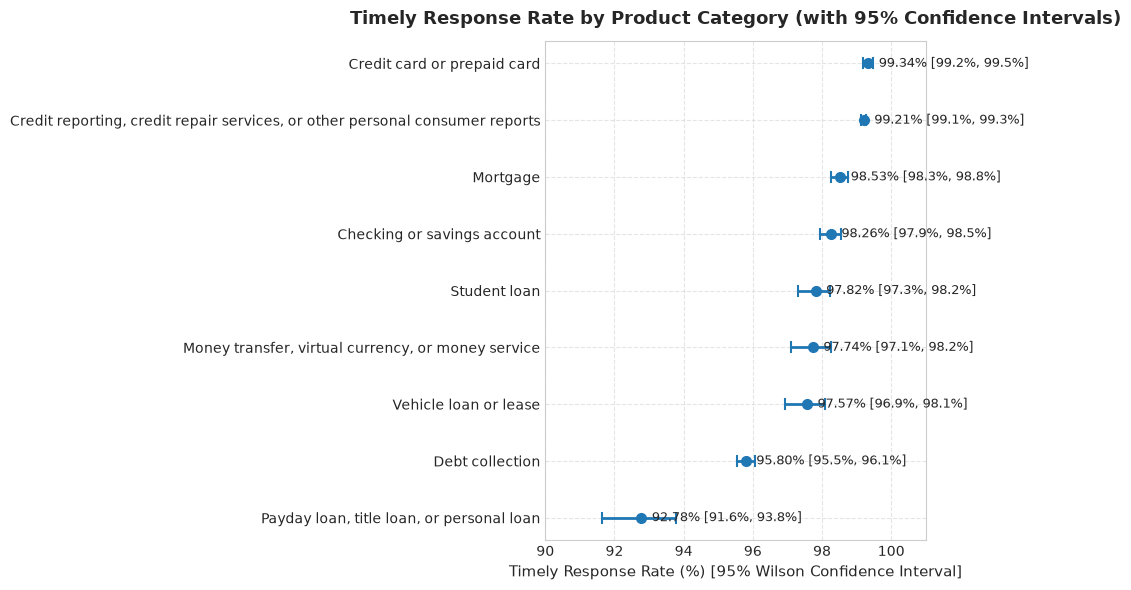

Saved outputs/figures/product_timeliness_intervals.png


In [4]:
# Chart: Timeliness by product with 95% Wilson confidence intervals
plot_data_a = product_timeliness_stats.sort_values('timely_percentage', ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(plot_data_a))
x_val = plot_data_a['timely_percentage']
x_err_low = x_val - plot_data_a['ci_lower_pct']
x_err_high = plot_data_a['ci_upper_pct'] - x_val

ax.errorbar(x_val, y_pos, xerr=[x_err_low, x_err_high], fmt='o', color='#1f77b4',
            ecolor='#1f77b4', elinewidth=2, capsize=4, capthick=1.5, markersize=7)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data_a['product'], fontsize=10)
ax.set_xlabel('Timely Response Rate (%) [95% Wilson Confidence Interval]', fontsize=11)
ax.set_title('Timely Response Rate by Product Category (with 95% Confidence Intervals)', fontsize=13, pad=12, fontweight='bold')
ax.set_xlim(90, 101)
ax.grid(True, linestyle='--', alpha=0.5)

for i, (_, row) in enumerate(plot_data_a.iterrows()):
    label_text = f"{row['timely_percentage']:.2f}% [{row['ci_lower_pct']:.1f}%, {row['ci_upper_pct']:.1f}%]"
    ax.text(row['timely_percentage'] + 0.3, i, label_text, va='center', fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / 'product_timeliness_intervals.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/product_timeliness_intervals.png")

### Statistical Interpretation — Analysis A
- **Test Statistic & p-value:** $\chi^2 = 1539.44$, $df = 8$, $p < 0.001$. At the $\alpha = 0.05$ significance level, the null hypothesis of independence is rejected.
- **Expected Counts:** The minimum expected cell frequency is $39.30$ (in Payday loan $\times$ Untimely), well above the standard threshold of 5, confirming test validity.
- **Effect Size:** Cramer's $V = 0.1146$, indicating a small-to-moderate association between product category and response timeliness.
- **Practical Interpretation:** Although statistically significant due to the large sample size ($N = 117,214$), the practical difference across most products is narrow: 7 of 9 product categories exhibit timeliness rates above 97%. Credit card products record the highest timeliness at 99.34% [99.18%, 99.47%], while Payday loans record the lowest at 92.78% [91.63%, 93.79%]. Payday loans represent the main operational outlier in timeliness.

## Analysis B — Recorded Relief Across Products

### Business Question
How do recorded relief categories vary across financial products?

### Hypotheses
- **Null Hypothesis ($H_0$):** The proportion of complaints with recorded relief is independent of financial product category.
- **Alternative Hypothesis ($H_1$):** The proportion of complaints with recorded relief is associated with financial product category.

### Method
- **Feature Used:** `has_recorded_relief` (True for `Closed with monetary relief` and `Closed with non-monetary relief`; False otherwise).
- **Test:** Pearson's Chi-Square Test of Independence on the $9 \times 2$ contingency table.
- **Effect Size:** Cramer's $V$.
- **Confidence Intervals:** 95% Wilson score confidence interval for recorded-relief proportions.

*Clarification:* Recorded relief indicates the company's administrative disposition reported to CFPB. It does not represent independently verified customer satisfaction, nor does it establish that product category causes relief outcomes.

In [5]:
# 1. Calculate relief counts and breakdown (monetary vs non-monetary)
df['monetary_relief'] = df['company_response_to_consumer'] == 'Closed with monetary relief'
df['non_monetary_relief'] = df['company_response_to_consumer'] == 'Closed with non-monetary relief'

pr_summary = df.groupby('product').agg(
    total_complaints=('has_recorded_relief', 'count'),
    relief_count=('has_recorded_relief', 'sum'),
    no_relief_count=('has_recorded_relief', lambda x: (~x).sum()),
    monetary_count=('monetary_relief', 'sum'),
    non_monetary_count=('non_monetary_relief', 'sum')
).reset_index()

n_b = pr_summary['total_complaints']
p_b = pr_summary['relief_count'] / n_b
denom_b = 1 + z**2 / n_b
center_b = p_b + z**2 / (2 * n_b)
margin_b = z * np.sqrt((p_b * (1 - p_b) / n_b) + (z**2 / (4 * n_b**2)))

product_recorded_relief = pd.DataFrame({
    'product': pr_summary['product'],
    'total_complaints': n_b,
    'relief_count': pr_summary['relief_count'],
    'no_relief_count': pr_summary['no_relief_count'],
    'relief_percentage': (p_b * 100).round(2),
    'monetary_count': pr_summary['monetary_count'],
    'monetary_percentage': ((pr_summary['monetary_count'] / n_b) * 100).round(2),
    'non_monetary_count': pr_summary['non_monetary_count'],
    'non_monetary_percentage': ((pr_summary['non_monetary_count'] / n_b) * 100).round(2),
    'ci_lower_pct': ((center_b - margin_b) / denom_b * 100).round(2),
    'ci_upper_pct': ((center_b + margin_b) / denom_b * 100).round(2)
}).sort_values('total_complaints', ascending=False).reset_index(drop=True)

# Export analytical table
product_recorded_relief.to_csv(tables_dir / 'product_recorded_relief.csv', index=False)
print("Saved outputs/tables/product_recorded_relief.csv")
display(product_recorded_relief)

# 2. Chi-square test of independence
contingency_b = pr_summary.set_index('product')[['relief_count', 'no_relief_count']]
chi2_b, p_b_val, dof_b, expected_b = stats.chi2_contingency(contingency_b)
cramer_v_b = np.sqrt(chi2_b / len(df))

print("\n=== CHI-SQUARE TEST: PRODUCT VS. RECORDED RELIEF ===")
print(f"Chi-square statistic (χ²): {chi2_b:.4f}")
print(f"Degrees of freedom:      {dof_b}")
print(f"p-value:                 {p_b_val:.4e}")
print(f"Cramer's V:              {cramer_v_b:.4f}")
print(f"Minimum expected count:  {expected_b.min():.2f} (all cells >= 5: {expected_b.min() >= 5})")

Saved outputs/tables/product_recorded_relief.csv


,product,total_complaints,relief_count,no_relief_count,relief_percentage,monetary_count,monetary_percentage,non_monetary_count,non_monetary_percentage,ci_lower_pct,ci_upper_pct
0,"Credit reporting, credit repair services, or o...",55558,11956,43602,21.52,268,0.48,11688,21.04,21.18,21.86
1,Debt collection,22287,2514,19773,11.28,185,0.83,2329,10.45,10.87,11.70
2,Credit card or prepaid card,11571,3252,8319,28.10,2134,18.44,1118,9.66,27.29,28.93
3,Mortgage,9449,605,8844,6.40,331,3.50,274,2.90,5.93,6.91
4,Checking or savings account,6915,1956,4959,28.29,1654,23.92,302,4.37,27.24,29.36
5,Student loan,3941,357,3584,9.06,90,2.28,267,6.77,8.20,10.00
6,Vehicle loan or lease,2713,287,2426,10.58,120,4.42,167,6.16,9.48,11.79
7,"Money transfer, virtual currency, or money ser...",2563,435,2128,16.97,247,9.64,188,7.34,15.57,18.47
8,"Payday loan, title loan, or personal loan",2217,193,2024,8.71,89,4.01,104,4.69,7.60,9.95



=== CHI-SQUARE TEST: PRODUCT VS. RECORDED RELIEF ===
Chi-square statistic (χ²): 3677.8838
Degrees of freedom:      8
p-value:                 0.0000e+00
Cramer's V:              0.1771
Minimum expected count:  407.69 (all cells >= 5: True)


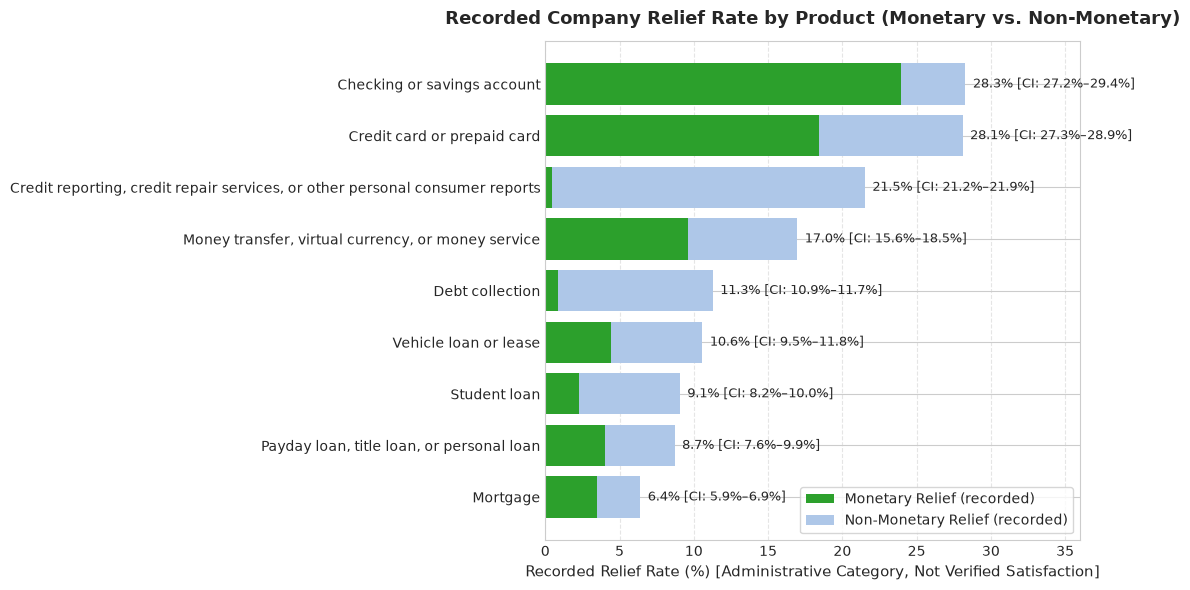

Saved outputs/figures/recorded_relief_by_product.png


In [6]:
# Chart: Recorded relief by product distinguishing monetary and non-monetary relief
plot_data_b = product_recorded_relief.sort_values('relief_percentage', ascending=True)
fig, ax = plt.subplots(figsize=(11, 6))

y_pos_b = np.arange(len(plot_data_b))
b1 = ax.barh(y_pos_b, plot_data_b['monetary_percentage'], color='#2ca02c', label='Monetary Relief (recorded)')
b2 = ax.barh(y_pos_b, plot_data_b['non_monetary_percentage'], left=plot_data_b['monetary_percentage'], color='#aec7e8', label='Non-Monetary Relief (recorded)')

ax.set_yticks(y_pos_b)
ax.set_yticklabels(plot_data_b['product'], fontsize=10)
ax.set_xlabel('Recorded Relief Rate (%) [Administrative Category, Not Verified Satisfaction]', fontsize=11)
ax.set_title('Recorded Company Relief Rate by Product (Monetary vs. Non-Monetary)', fontsize=13, pad=12, fontweight='bold')
ax.set_xlim(0, 36)
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True)

for i, (_, row) in enumerate(plot_data_b.iterrows()):
    total_pct = row['relief_percentage']
    label_text = f"{total_pct:.1f}% [CI: {row['ci_lower_pct']:.1f}%–{row['ci_upper_pct']:.1f}%]"
    ax.text(total_pct + 0.5, i, label_text, va='center', fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / 'recorded_relief_by_product.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/recorded_relief_by_product.png")

### Statistical Interpretation — Analysis B
- **Test Statistic & p-value:** $\chi^2 = 3677.88$, $df = 8$, $p < 0.001$. The null hypothesis of independence is rejected at $\alpha = 0.05$.
- **Expected Counts:** The minimum expected cell frequency is $407.69$ (Payday loan $\times$ Relief), confirming robustness of the chi-square approximation.
- **Effect Size:** Cramer's $V = 0.1771$, reflecting a moderate association between financial product category and recorded relief.
- **Practical Interpretation:** The nature and rate of recorded relief differ markedly by product architecture:
  - **Checking/savings accounts** (28.29% total relief) and **Credit cards** (28.10% total relief) exhibit the highest relief proportions, predominantly composed of *monetary relief* (23.92% and 18.44% respectively), reflecting account fee refunds or transaction adjustments.
  - **Credit reporting** exhibits a 21.52% total relief rate, but this is almost exclusively *non-monetary relief* (21.04% non-monetary vs. 0.48% monetary), corresponding to bureau record updates or dispute suppressions.
  - **Mortgage** records the lowest relief rate at 6.40% [5.93%, 6.91%].
- **Limitations:** These figures reflect company-reported closure statuses, not verified customer satisfaction or case merit.

## Analysis C — Complaint Narrative Length Across Products

### Business Question
Do customers write complaints of different lengths across financial products?

### Hypotheses
- **Null Hypothesis ($H_0$):** The distribution of narrative word counts is identical across all financial product categories.
- **Alternative Hypothesis ($H_1$):** At least one financial product category has a narrative word count distribution that differs from the others.

### Method
- **Metric:** `narrative_word_count` (cleaned narrative word count).
- **Distributional Properties:** The data is heavily right-skewed with extreme values (max 6,014 words), making parametric ANOVA unsuitable.
- **Test:** Kruskal-Wallis $H$-test (`scipy.stats.kruskal`), a non-parametric rank-based test that compares medians and rank sums across independent groups.
- **Effect Size:** Eta-squared based on the $H$-statistic: $\eta^2_H = \frac{H - k + 1}{n - k}$, where $k = 9$ and $n = 117,214$. It measures the proportion of variance in the ranks accounted for by the product groups (0.01 = small, 0.06 = medium, 0.14 = large).

*Caution:* Longer complaints do not indicate that a product issue is more difficult, more important, or more likely to be resolved.

In [7]:
# 1. Calculate narrative length summary statistics across products
nl_summary = df.groupby('product')['narrative_word_count'].agg(
    total_complaints='count',
    mean_words='mean',
    median_words='median',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75)
).reset_index()

nl_summary['iqr'] = (nl_summary['q75'] - nl_summary['q25']).round(1)
nl_summary['mean_words'] = nl_summary['mean_words'].round(1)
nl_summary['median_words'] = nl_summary['median_words'].round(1)
nl_summary['q25'] = nl_summary['q25'].round(1)
nl_summary['q75'] = nl_summary['q75'].round(1)

narrative_length_by_product = nl_summary.sort_values('total_complaints', ascending=False).reset_index(drop=True)

# Export analytical table
narrative_length_by_product.to_csv(tables_dir / 'narrative_length_by_product.csv', index=False)
print("Saved outputs/tables/narrative_length_by_product.csv")
display(narrative_length_by_product)

# 2. Kruskal-Wallis test across product groups
groups_c = [group['narrative_word_count'].values for _, group in df.groupby('product')]
h_stat, p_c_val = stats.kruskal(*groups_c)
k_groups = len(groups_c)
n_total = len(df)
eta_sq_c = (h_stat - k_groups + 1) / (n_total - k_groups)
epsilon_sq_c = h_stat / (n_total - 1)

print("\n=== KRUSKAL-WALLIS TEST: NARRATIVE WORD COUNT BY PRODUCT ===")
print(f"Kruskal-Wallis H statistic: {h_stat:.4f}")
print(f"Degrees of freedom (k - 1): {k_groups - 1}")
print(f"p-value:                    {p_c_val:.4e}")
print(f"Eta-squared (η²_H):         {eta_sq_c:.4f}")
print(f"Epsilon-squared (ε²):       {epsilon_sq_c:.4f}")

Saved outputs/tables/narrative_length_by_product.csv


,product,total_complaints,mean_words,median_words,q25,q75,iqr
0,"Credit reporting, credit repair services, or o...",55558,153.2,95.0,51.0,171.0,120.0
1,Debt collection,22287,169.3,115.0,59.0,212.0,153.0
2,Credit card or prepaid card,11571,241.8,174.0,99.0,295.0,196.0
3,Mortgage,9449,322.7,223.0,130.0,381.0,251.0
4,Checking or savings account,6915,255.4,179.0,102.0,314.0,212.0
5,Student loan,3941,238.0,175.0,100.0,295.0,195.0
6,Vehicle loan or lease,2713,241.7,176.0,100.0,301.0,201.0
7,"Money transfer, virtual currency, or money ser...",2563,242.0,170.0,96.0,293.0,197.0
8,"Payday loan, title loan, or personal loan",2217,205.3,143.0,79.0,244.0,165.0



=== KRUSKAL-WALLIS TEST: NARRATIVE WORD COUNT BY PRODUCT ===
Kruskal-Wallis H statistic: 11789.1288
Degrees of freedom (k - 1): 8
p-value:                    0.0000e+00
Eta-squared (η²_H):         0.1005
Epsilon-squared (ε²):       0.1006


C:\Users\nayan\AppData\Local\Temp\ipykernel_29728\3191368150.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(


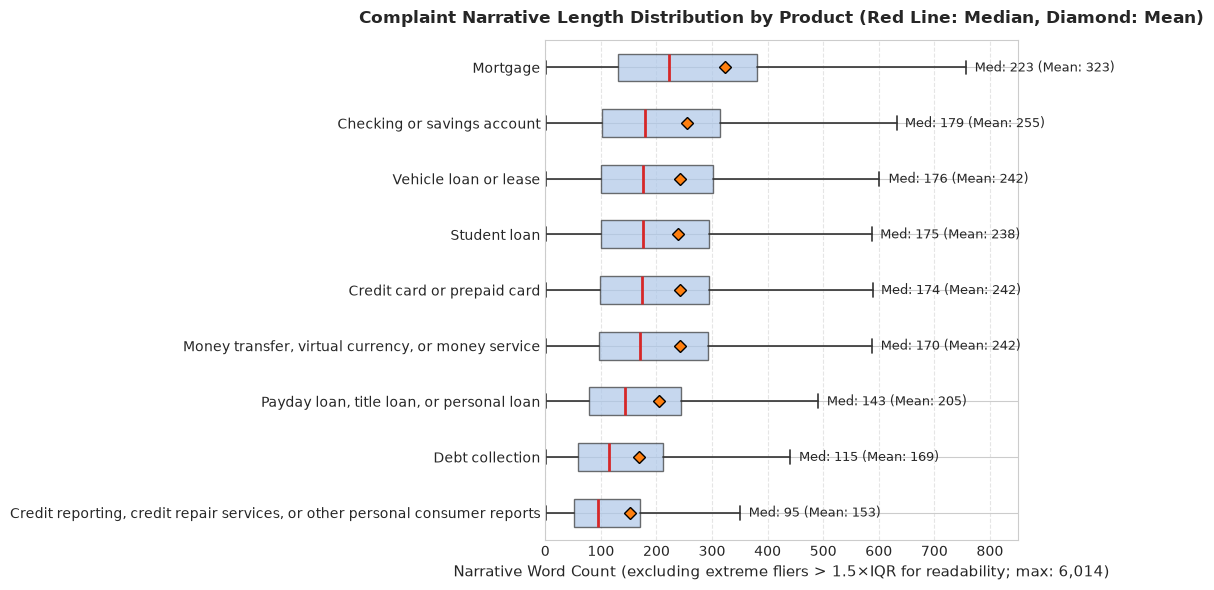

Saved outputs/figures/narrative_length_by_product.png


In [8]:
# Chart: Narrative length distribution across products (boxplot ordered by median)
order_by_median = narrative_length_by_product.sort_values('median_words', ascending=True)
ordered_names = order_by_median['product'].tolist()
box_data = [df[df['product'] == p]['narrative_word_count'].values for p in ordered_names]

fig, ax = plt.subplots(figsize=(11, 6))
bp = ax.boxplot(
    box_data, vert=False, patch_artist=True, showmeans=True, showfliers=False,
    medianprops=dict(color='#d62728', linewidth=2),
    meanprops=dict(marker='D', markeredgecolor='black', markerfacecolor='#ff7f0e', markersize=6),
    boxprops=dict(facecolor='#aec7e8', alpha=0.7, edgecolor='#333333'),
    whiskerprops=dict(color='#333333', linewidth=1.2),
    capprops=dict(color='#333333', linewidth=1.2)
)

ax.set_yticklabels(ordered_names, fontsize=10)
ax.set_xlabel('Narrative Word Count (excluding extreme fliers > 1.5×IQR for readability; max: 6,014)', fontsize=11)
ax.set_title('Complaint Narrative Length Distribution by Product (Red Line: Median, Diamond: Mean)', fontsize=12, pad=12, fontweight='bold')
ax.set_xlim(0, 850)
ax.grid(axis='x', linestyle='--', alpha=0.5)

for i, (_, row) in enumerate(order_by_median.iterrows()):
    med = row['median_words']
    avg = row['mean_words']
    ax.text(row['q75'] + row['iqr'] * 1.5 + 15, i + 1, f"Med: {med:.0f} (Mean: {avg:.0f})", va='center', fontsize=9)

plt.tight_layout()
plt.savefig(figures_dir / 'narrative_length_by_product.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/narrative_length_by_product.png")

### Statistical Interpretation — Analysis C
- **Test Statistic & p-value:** Kruskal-Wallis $H = 11789.13$, $df = 8$, $p < 0.001$. The null hypothesis of equal rank distributions across product categories is rejected at $\alpha = 0.05$.
- **Effect Size:** $\eta^2_H = 0.1005$ (epsilon-squared $\epsilon^2 = 0.1006$). Approximately $10.05\%$ of the variance in narrative length ranks is explained by the financial product group, representing a moderate-to-large effect size in non-parametric terms.
- **Practical Interpretation:**
  - **Highest Median Narrative Length:** *Mortgage* complaints exhibit the longest narratives, with a median of $223.0$ words, a mean of $322.7$ words, and an IQR of $251.0$ words.
  - **Lowest Median Narrative Length:** *Credit reporting, credit repair services, or other* complaints have the shortest narratives, with a median of $95.0$ words, a mean of $153.2$ words, and an IQR of $120.0$ words.
  - **Substantial Gap:** The median narrative in Mortgage complaints is $2.35\times$ as long as that in Credit reporting complaints, reflecting concise dispute templates in credit reporting versus narrative descriptions in mortgage servicing.
- **Limitations:** Text length reflects descriptive volume in this published sample; it does not indicate issue complexity, consumer distress level, or complaint legitimacy.

## Key Findings

Based strictly on the statistical analyses performed on the 117,214 complaints in this dataset:

1. **Product Category Is Statistically Associated with Response Timeliness, but Practical Variation Is Small:**
   - *What was observed:* A chi-square test of independence between product category and procedural timeliness (`timely_response`) was statistically significant ($\chi^2 = 1539.44$, $p < 0.001$, $df = 8$).
   - *Statistical evidence:* The effect size is small (Cramer's $V = 0.1146$). The overall portfolio timeliness is $98.23\%$, with 7 of 9 product categories exceeding $97\%$ timeliness. Credit card complaints achieve the highest rate ($99.34\%$ [95% CI: $99.18\%$–$99.47\%$]), while Payday loan complaints record the lowest ($92.78\%$ [95% CI: $91.63\%$–$93.79\%$]).
   - *Business analyst meaning:* While the large sample size yields a tiny p-value, response timeliness is uniformly high across major banking and credit products. Payday loans represent the primary operational area with elevated untimely responses ($7.22\%$ untimely vs. $1.77\%$ overall).

2. **Recorded Relief Rates and Relief Forms Differ Substantially Across Products:**
   - *What was observed:* A chi-square test between product category and recorded relief (`has_recorded_relief`) revealed a significant and moderate association ($\chi^2 = 3677.88$, $p < 0.001$, $df = 8$, Cramer's $V = 0.1771$).
   - *Statistical evidence:* Recorded relief rates span from $6.40\%$ [95% CI: $5.93\%$–$6.91\%$] in Mortgage to $28.29\%$ [95% CI: $27.24\%$–$29.36\%$] in Checking/savings. Furthermore, the *type* of relief diverges: Checking/savings ($23.92\%$) and Credit cards ($18.44\%$) are dominated by monetary relief, whereas Credit reporting relief ($21.52\%$ total) is $97.8\%$ non-monetary ($21.04\%$ non-monetary vs. $0.48\%$ monetary).
   - *Business analyst meaning:* Company resolution pathways align with operational product mechanisms: transaction accounts commonly utilize financial reimbursement (e.g. fee waivers), whereas credit reporting disputes predominantly involve administrative data corrections.

3. **Narrative Word Counts Differ Significantly Across Products with Moderate Effect Size:**
   - *What was observed:* A non-parametric Kruskal-Wallis test showed that narrative word counts differ significantly across financial products ($H = 11789.13$, $p < 0.001$, $df = 8$).
   - *Statistical evidence:* The effect size is moderate ($\eta^2_H = 0.1005$), meaning approximately $10.05\%$ of rank variance in narrative length is attributable to product category. Mortgage complaints have the highest median length ($223.0$ words, mean $322.7$, IQR $251.0$), while Credit reporting complaints have the lowest median length ($95.0$ words, mean $153.2$, IQR $120.0$).
   - *Business analyst meaning:* Complaint text volumes vary systematically by domain. Automated text processing and triage systems must be configured to handle varying text density, with mortgage complaints requiring capacity for longer prose and credit reporting dominated by concise, templated statements.

4. **Large Sample Size Amplifies Statistical Significance Over Practical Impact:**
   - *What was observed:* All three hypothesis tests produced extreme test statistics and $p < 0.001$.
   - *Statistical evidence:* With $N = 117,214$, even minor percentage differences attain statistical significance. Effect size metrics (Cramer's $V$ of $0.1146$ and $0.1771$; $\eta^2_H$ of $0.1005$) provide the necessary calibration of practical importance.
   - *Business analyst meaning:* Analysts and decision-makers should rely on effect sizes and confidence intervals rather than p-values alone to avoid treating minor operational differences as major business anomalies.

5. **Sample Composition and Observational Constraints:**
   - *What was observed:* The dataset reflects historical complaints where consumers specifically consented to share narratives publicly, and includes $10,854$ duplicate narrative records.
   - *Statistical evidence:* All $117,214$ records possess published narratives, and $15,765$ total records share identical narrative text with at least one other record.
   - *Business analyst meaning:* Results describe this published-narrative historical sample and cannot be generalized to the entire population of financial consumers without selection-bias adjustment. Duplicate narratives also slightly attenuate the strict independence assumption underlying standard hypothesis tests.